# INCT — Etapa 1: treinamento da MLP em Burgers

**Objetivo:** acompanhar o treinamento já feito no cluster para larguras **8, 16, 32, 64 e 128**, mantendo 3 camadas ocultas. Este notebook **não treina novamente**: apenas lê os arquivos de `runs/jobs/2318/results`.

Nesta versão inicial, veremos o progresso disponível, RMSE por largura e curvas de treino/validação (média ± desvio-padrão entre sementes). Conforme os experimentos terminarem, basta executar as células novamente.

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Se o notebook estiver em notebooks/, a raiz é a pasta anterior.
ROOT = Path.cwd()
if not (ROOT / "runs").exists():
    ROOT = ROOT.parent

JOB_ID = "2318"  # Etapa 1: largura da MLP, Burgers
DATA = ROOT / "runs" / "jobs" / JOB_ID / "results" / "burgers"
MODELS = ["mlp_width_8", "mlp_width_16", "mlp", "mlp_width_64", "mlp_width_128"]
LABELS = {"mlp_width_8": "8", "mlp_width_16": "16", "mlp": "32", "mlp_width_64": "64", "mlp_width_128": "128"}

print("Resultados:", DATA)
print("Diretório existe:", DATA.exists())

Resultados: /home/camaral/inct_cq_hybrid_nn/runs/jobs/2318/results/burgers
Diretório existe: True


## 1. Treinamentos concluídos e desempenho

Cada `metrics.json` representa um treinamento concluído. A tabela mostra média e **desvio-padrão entre sementes**, sem misturar experimentos ainda em andamento.

In [13]:
import json

rows = []
for model in MODELS:
    for p in sorted((DATA / model).glob("seed_*/metrics.json")):
        seed = int(p.parent.name.replace("seed_", ""))
        metrics = json.loads(p.read_text())
        rows.append({"model": model, "width": int(LABELS[model]), "seed": seed,
                     "rmse": metrics.get("rmse", np.nan),
                     "relative_l2": metrics.get("relative_l2", np.nan),
                     "time_s": metrics.get("time_s", np.nan),
                     "parameters": metrics.get("parameters", np.nan)})

df = pd.DataFrame(rows)
if df.empty:
    print("Ainda não existem metrics.json nesta campanha. Confira JOB_ID e a execução PBS.")
else:
    table = (df.groupby("width").agg(
        sementes=("seed", "nunique"), rmse_medio=("rmse", "mean"),
        rmse_dp=("rmse", "std"), l2_medio=("relative_l2", "mean"),
        l2_dp=("relative_l2", "std"), tempo_medio_s=("time_s", "mean"),
        parametros=("parameters", "first"))).sort_index()
    display(table.round(6))

,sementes,rmse_medio,rmse_dp,l2_medio,l2_dp,tempo_medio_s,parametros
width,,,,,,,
8,10,0.031370,0.013006,0.141700,0.058747,1.7235,177
16,10,0.019051,0.006868,0.086055,0.031025,1.7592,609
32,10,0.012052,0.004193,0.054440,0.018940,1.8806,2241
64,10,0.011649,0.003301,0.052620,0.014911,2.0997,8577
128,10,0.013252,0.003088,0.059859,0.013951,2.8200,33537


## 2. RMSE versus número de neurônios

As barras representam **± 1 desvio-padrão** entre as sementes concluídas; isso descreve a dispersão entre execuções, não um intervalo de confiança.

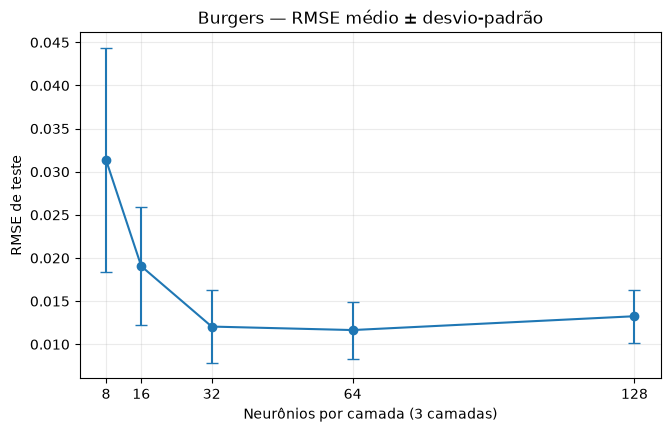

In [14]:
if not df.empty:
    summary = df.groupby("width")["rmse"].agg(["mean", "std", "count"]).sort_index()
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.errorbar(summary.index, summary["mean"], yerr=summary["std"].fillna(0),
                marker="o", capsize=4, linewidth=1.5)
    ax.set(xlabel="Neurônios por camada (3 camadas)", ylabel="RMSE de teste",
           title="Burgers — RMSE médio ± desvio-padrão")
    ax.set_xticks(summary.index)
    ax.grid(alpha=0.25)
    plt.show()

## 3. Curvas de convergência

MSE de validação ao longo das épocas: **média ± desvio-padrão entre sementes**. Cada curva inclui apenas históricos que já foram salvos; as bandas podem ficar incompletas enquanto o job executa.

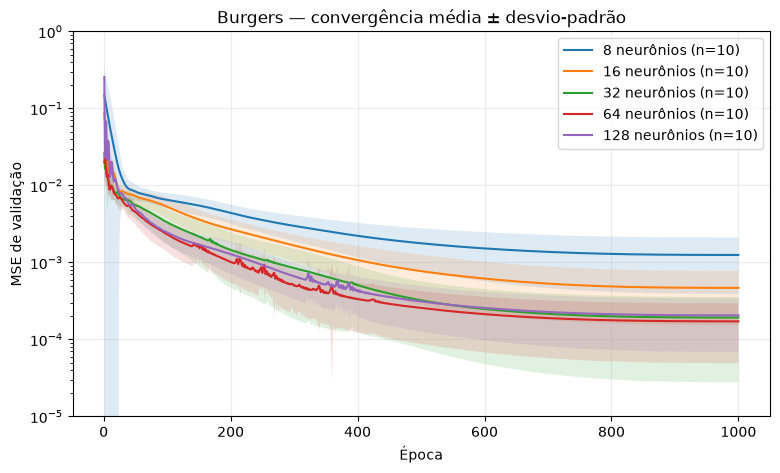

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
found = False
for model in MODELS:
    series = []
    for path in sorted((DATA / model).glob("seed_*/history.csv")):
        h = pd.read_csv(path)
        if {"epoch", "val_mse"}.issubset(h.columns):
            series.append(h.set_index("epoch")["val_mse"].rename(path.parent.name))
    if not series:
        continue
    found = True
    mat = pd.concat(series, axis=1)
    mean = mat.mean(axis=1)
    std = mat.std(axis=1).fillna(0)
    ax.plot(mean.index, mean.clip(lower=1e-12), label=f"{LABELS[model]} neurônios (n={len(series)})")
    ax.fill_between(mean.index, (mean - std).clip(lower=1e-12),
                    (mean + std).clip(lower=1e-12), alpha=0.14)
if found:
    ax.set(yscale="log", xlabel="Época", ylabel="MSE de validação",
           title="Burgers — convergência média ± desvio-padrão")
    ax.grid(alpha=0.25)
    ax.set_ylim(1e-5, 1)
    ax.legend()
    plt.show()
else:
    plt.close(fig)
    print("Nenhum history.csv encontrado ainda.")
    

### Próximos acréscimos

Quando quisermos, acrescentaremos aqui: tempo e custo computacional, superfícies 2D, perfis em três tempos, RMSE por instante e comparações pareadas entre sementes. Não é necessário refazer o treinamento para produzir esses gráficos.


## 5. Erro relativo L2 por número de neurônios

Comparamos o erro relativo L2 das diferentes larguras da MLP na equação de Burgers.

Os pontos representam a média das 10 sementes e as barras de erro representam o desvio-padrão entre execuções.


,mean,std,count
neurons,,,
8,0.141700,0.058747,10
16,0.086055,0.031025,10
32,0.054440,0.018940,10
64,0.052620,0.014911,10
128,0.059859,0.013951,10


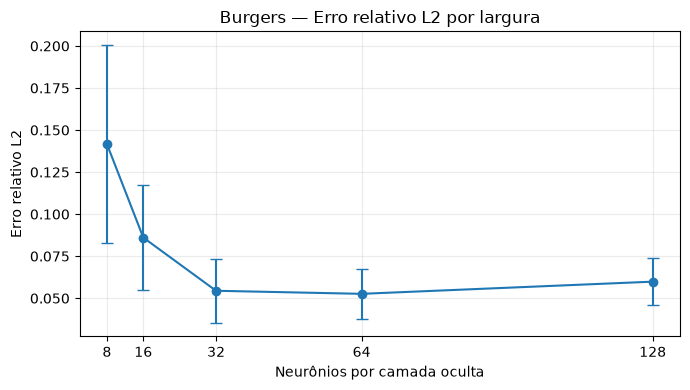

In [16]:


widths = {
    "mlp_width_8": 8,
    "mlp_width_16": 16,
    "mlp": 32,
    "mlp_width_64": 64,
    "mlp_width_128": 128,
}

dados = df[df["model"].isin(widths)].copy()
dados["neurons"] = dados["model"].map(widths)

resumo = (
    dados.groupby("neurons")["relative_l2"]
    .agg(["mean", "std", "count"])
    .sort_index()
)

display(resumo)

plt.figure(figsize=(7, 4))
plt.errorbar(
    resumo.index,
    resumo["mean"],
    yerr=resumo["std"].fillna(0),
    fmt="o-",
    capsize=4,
)

plt.xticks(list(widths.values()))
plt.xlabel("Neurônios por camada oculta")
plt.ylabel("Erro relativo L2")
plt.title("Burgers — Erro relativo L2 por largura")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()



## 6. Ablação de profundidade da MLP

Nesta etapa, avaliamos o impacto do número de camadas ocultas na aproximação da solução analítica da equação de Burgers.

Todas as arquiteturas possuem 64 neurônios por camada, ativação tanh e as mesmas configurações de treinamento.

São consideradas cinco profundidades: 1, 2, 3, 4 e 5 camadas ocultas, com 10 sementes por configuração.


In [18]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "runs").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Jobs da campanha de profundidade
jobs = {
    2: ("2320", "mlp_64_depth_2"),
    3: ("2318", "mlp_width_64"),
    4: ("2321", "mlp_64_depth_4"),
    5: ("2322", "mlp_64_depth_5"),
}

registros = []

# Profundidade 1: identifica o job automaticamente
arquivos = list(
    (ROOT / "runs/jobs").glob(
        "*/results/burgers/mlp_64_depth_1/seed_*/metrics.json"
    )
)

for arquivo in arquivos:
    with open(arquivo) as f:
        dados = json.load(f)
    registros.append({
        **dados,
        "depth": 1,
        "seed": int(arquivo.parent.name.split("_")[-1])
    })

# Demais profundidades
for depth, (job, modelo) in jobs.items():
    pasta = ROOT / f"runs/jobs/{job}/results/burgers/{modelo}"

    for arquivo in pasta.glob("seed_*/metrics.json"):
        with open(arquivo) as f:
            dados = json.load(f)

        registros.append({
            **dados,
            "depth": depth,
            "seed": int(arquivo.parent.name.split("_")[-1])
        })

df_depth = pd.DataFrame(registros)

if df_depth.empty:
    raise FileNotFoundError("Nenhum resultado encontrado em runs/jobs.")

df_depth = df_depth.drop_duplicates(["depth", "seed"])

resumo_depth = (
    df_depth.groupby("depth")
    .agg(
        rmse_mean=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        l2_mean=("relative_l2", "mean"),
        l2_std=("relative_l2", "std"),
        time_mean=("time_s", "mean"),
        parameters=("parameters", "first"),
        seeds=("seed", "nunique")
    )
    .sort_index()
)

display(resumo_depth)

,rmse_mean,rmse_std,l2_mean,l2_std,time_mean,parameters,seeds
depth,,,,,,,
1,0.037479,0.005345,0.169295,0.024144,1.2616,257,10
2,0.017220,0.005898,0.077785,0.026642,1.7899,4417,10
3,0.011649,0.003301,0.052620,0.014911,2.0997,8577,10
4,0.009642,0.002232,0.043554,0.010081,2.9841,12737,10
5,0.008143,0.002729,0.036781,0.012329,3.1547,16897,10


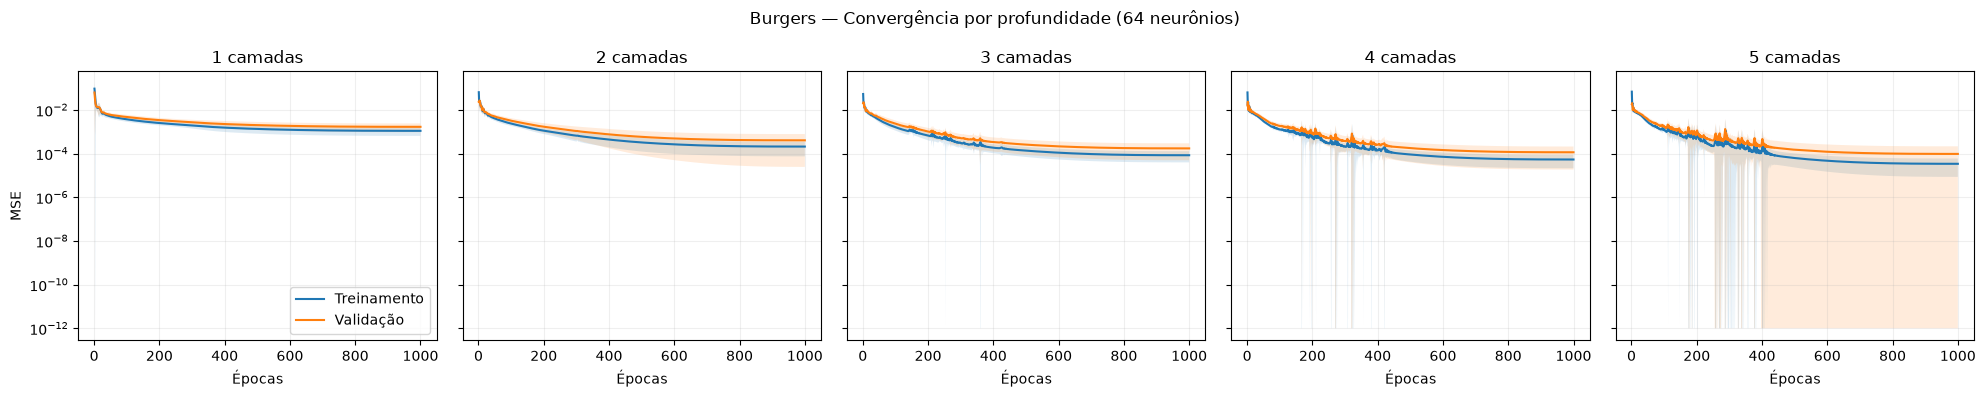

In [21]:

ROOT = Path.cwd()
while not (ROOT / "runs").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

modelos = {
    1: "mlp_64_depth_1",
    2: "mlp_64_depth_2",
    3: "mlp_width_64",
    4: "mlp_64_depth_4",
    5: "mlp_64_depth_5",
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for ax, (depth, modelo) in zip(axes, modelos.items()):

    arquivos = sorted(
        (ROOT / "runs/jobs").glob(
            f"*/results/burgers/{modelo}/seed_*/history.csv"
        )
    )

    historicos = []

    for arquivo in arquivos:
        hist = pd.read_csv(arquivo)
        hist["seed"] = arquivo.parent.name
        historicos.append(hist)

    if not historicos:
        ax.set_title(f"{depth} camadas\nSem dados")
        continue

    dados = pd.concat(historicos, ignore_index=True)

    for coluna, nome in [
        ("train_mse", "Treinamento"),
        ("val_mse", "Validação"),
    ]:
        if coluna not in dados.columns:
            continue

        curva = dados.groupby("epoch")[coluna].agg(["mean", "std"])

        ax.plot(curva.index, curva["mean"], label=nome)
        ax.fill_between(
            curva.index,
            (curva["mean"] - curva["std"].fillna(0)).clip(lower=1e-12),
            curva["mean"] + curva["std"].fillna(0),
            alpha=0.15,
        )

    ax.set_title(f"{depth} camadas")
    ax.set_xlabel("Épocas")
    ax.set_yscale("log")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("MSE")
axes[0].legend()

plt.suptitle("Burgers — Convergência por profundidade (64 neurônios)")
plt.tight_layout()
plt.show()



## 7. RMSE versus número de camadas ocultas

Comparamos o RMSE médio de cada arquitetura.

As barras de erro representam o desvio-padrão entre as sementes, permitindo avaliar simultaneamente precisão e estabilidade.


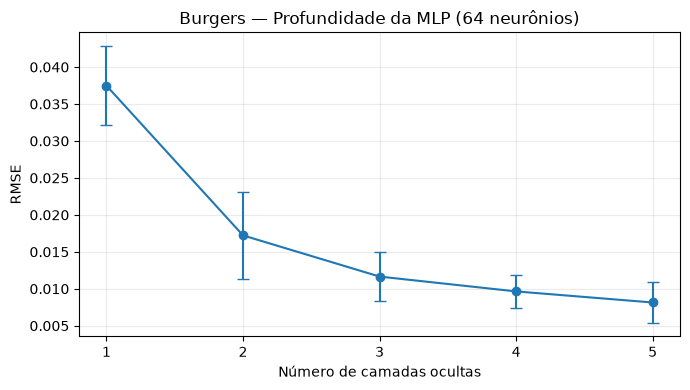

In [19]:

plt.figure(figsize=(7, 4))

plt.errorbar(
    resumo_depth.index,
    resumo_depth["rmse_mean"],
    yerr=resumo_depth["rmse_std"].fillna(0),
    fmt="o-",
    capsize=4,
    linewidth=1.5,
)

plt.xticks([1, 2, 3, 4, 5])
plt.xlabel("Número de camadas ocultas")
plt.ylabel("RMSE")
plt.title("Burgers — Profundidade da MLP (64 neurônios)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()



## 8. RMSE versus número de parâmetros

Analisamos a relação entre a complexidade da MLP e sua precisão na aproximação da equação de Burgers.

O número de parâmetros treináveis representa a complexidade da arquitetura, enquanto o RMSE mede o erro de aproximação.

Os pontos representam a média entre sementes, e as barras de erro indicam o desvio-padrão do RMSE.


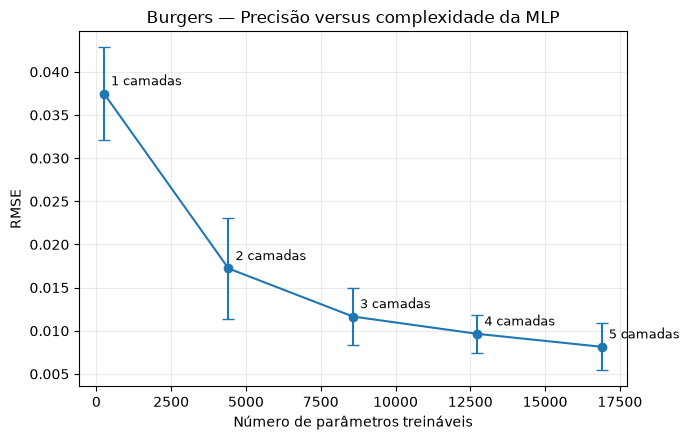

In [20]:

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.errorbar(
    resumo_depth["parameters"],
    resumo_depth["rmse_mean"],
    yerr=resumo_depth["rmse_std"].fillna(0),
    fmt="o-",
    capsize=4,
)

for depth, row in resumo_depth.iterrows():
    ax.annotate(
        f"{depth} camadas",
        (row["parameters"], row["rmse_mean"]),
        xytext=(5, 6),
        textcoords="offset points",
        fontsize=9,
    )

ax.set_xlabel("Número de parâmetros treináveis")
ax.set_ylabel("RMSE")
ax.set_title("Burgers — Precisão versus complexidade da MLP")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()
